# L9 — PCA and the SVD: Follow-Along Examples
**MCS 3950 Computer Vision · UPEI · Fall 2026**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andrewgodbout/MCS-3950-Sandbox/blob/main/Notebooks/L09-PCA-SVD/L9_PCA_SVD.ipynb)

This notebook accompanies **Lecture 9**. An 8×8 patch of an aerial photograph is a list of 64
numbers — a point in a 64-dimensional space. Real patches do not fill that space: they crowd
into a thin slice of it. **Principal component analysis (PCA)** finds that slice, and the
**singular value decomposition (SVD)** is how we compute it. On Monday (L8) we used the SVD as a
black box to fit a homography; today we open the box. Every number on the slides is produced here.

| Section | Topic |
|---------|-------|
| 0 | Get the imagery |
| 1 | Images are points in a high-dimensional space |
| 2 | PCA in two dimensions: neighbouring pixels |
| 3 | The recipe, and the notation $X, \mu, W, Z, \hat X$ |
| 4 | The SVD |
| 5 | Rank-$k$ approximation of one image |
| 6 | The other end of the SVD: L8's DLT |
| 7 | Eigen-patches and explained variance |
| 8 | Reconstruction error and choosing $k$ |
| 9 | Eigenfaces |
| 10 | Distance from face space |
| 11 | PCA in your pipeline: colour bands and SIFT descriptors |
| 12 | Pitfalls: centring and outliers |

> **Assignment 1** (PCA on animal faces) uses the same notation as this notebook. It asks you to
> package these steps into your own class — this notebook does each step inline, once.

In [2]:
import time
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
GOLD, RED, TEAL, GREEN, NAVY, PURPLE, GREY = ("#C8962C", "#B82828", "#1A7A8A", "#2E7D50",
                                              "#1A3A5C", "#7B4EA0", "#7A8FA6")

def tiles(vectors, shape, ncol, pad=1, scale=None, sym=False):
    # Arrange flattened images (rows of `vectors`) into one picture with blank gutters.
    # Default: each tile stretched to its own range. scale=(lo, hi): one fixed range.
    # sym=True: each tile divided by its largest |value| -> [-1, 1] (use with vmin=-1, vmax=1).
    h, w = shape
    n = len(vectors); nrow = int(np.ceil(n / ncol))
    out = np.full((nrow * (h + pad) - pad, ncol * (w + pad) - pad), np.nan)
    for i, v in enumerate(vectors):
        im = v.reshape(shape).astype(float)
        if sym:
            im = im / (np.abs(im).max() + 1e-12)
        else:
            lo, hi = scale if scale else (im.min(), im.max())
            im = np.clip((im - lo) / (hi - lo + 1e-12), 0, 1)
        r, c = divmod(i, ncol)
        out[r*(h+pad):r*(h+pad)+h, c*(w+pad):c*(w+pad)+w] = im
    return out

def psnr(a, b):
    return 20 * np.log10(255 / np.sqrt(np.mean((np.asarray(a, float) - b) ** 2)))

print(f"OpenCV {cv2.__version__}, NumPy {np.__version__}")

OpenCV 5.0.0, NumPy 2.5.3


---
## 0 · Get the imagery

**AL5** (twenty raw 1958 frames, the same zip as AL5 and L8) and the **2020 colour
orthophoto** from L2. The face images in section 9 ship with scikit-image — no download.
Safe to re-run.

In [3]:
import io, os, urllib.request, zipfile

BASE = ("https://raw.githubusercontent.com/andrewgodbout/"
        "MCS-3950-F26/main/Notebooks/data/")

def fetch_zip(name, needed):
    if all(os.path.exists(f) for f in needed):
        print(f"{name}: already present"); return
    with urllib.request.urlopen(BASE + name, timeout=120) as r:
        blob = r.read()
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        z.extractall(".")
    print(f"{name}: {len(blob)/1e6:.1f} MB downloaded and extracted")

def fetch_file(name):
    if os.path.exists(name):
        print(f"{name}: already present"); return
    urllib.request.urlretrieve(BASE + name, name)
    print(f"{name}: downloaded")

fetch_zip("AL5.zip", ["frames/16046-19.jpg", "frames/16046-20.jpg"])
fetch_file("eastern_pei_aerial_2020.png")

AL5.zip: already present
eastern_pei_aerial_2020.png: already present


### 0.1 — Training frames and a held-out frame

We learn from **18 of the 20 frames** and keep the L8 running pair, **16046-19 and 16046-20**,
out of training, so that everything we measure on them is a test on unseen imagery.

18 training frames, test frame 16046-19 is 953x1000


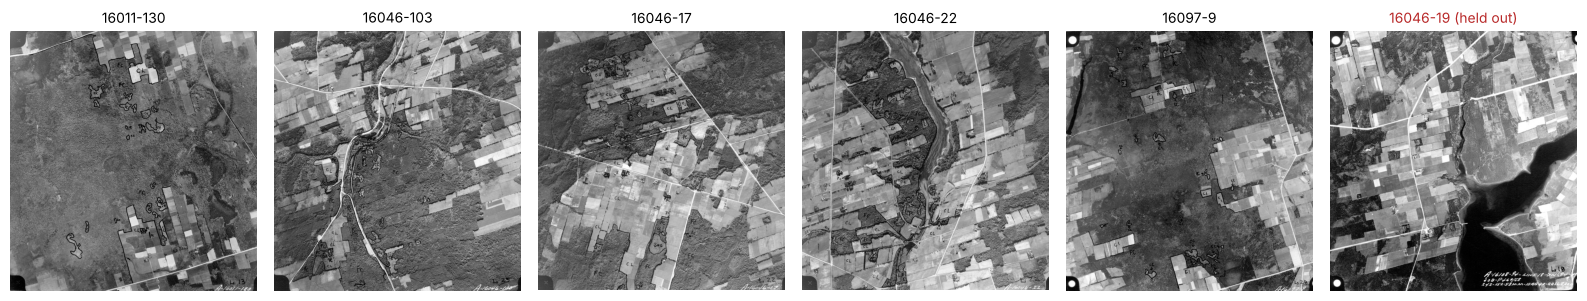

In [4]:
import glob
FRAMES = sorted(glob.glob("frames/*.jpg"))
TEST = ["frames/16046-19.jpg", "frames/16046-20.jpg"]
TRAIN = [f for f in FRAMES if f not in TEST]
A = cv2.imread(TEST[0], cv2.IMREAD_GRAYSCALE)            # frame 16046-19
print(f"{len(TRAIN)} training frames, test frame 16046-19 is {A.shape[1]}x{A.shape[0]}")

fig, axes = plt.subplots(1, 6, figsize=(16, 3.2))
for ax, f in zip(axes, TRAIN[::3] + [TEST[0]]):
    ax.imshow(cv2.imread(f, 0), cmap="gray"); ax.set_title(os.path.basename(f)[:-4], fontsize=10)
    ax.axis("off")
axes[-1].set_title("16046-19 (held out)", fontsize=10, color=RED)
plt.tight_layout(); plt.show()

---
## 1 · Images are points in a high-dimensional space

Cut an 8×8 patch out of a photograph and read its pixels row by row: 64 numbers. Every 8×8
patch is a point in $\mathbb{R}^{64}$, and so is every 8×8 array of random numbers. Almost all
of $\mathbb{R}^{64}$ looks like the right-hand panel below. Real patches are special: smooth,
correlated, mostly a single brightness with a little structure. The question for today is
**how many numbers you really need** to describe one.

We sample 3,000 random patches from each training frame, 40 px in from the border (the frame
edges hold black film margin and fiducial marks).

X: n = 54,000 patches  x  d = 64 pixels


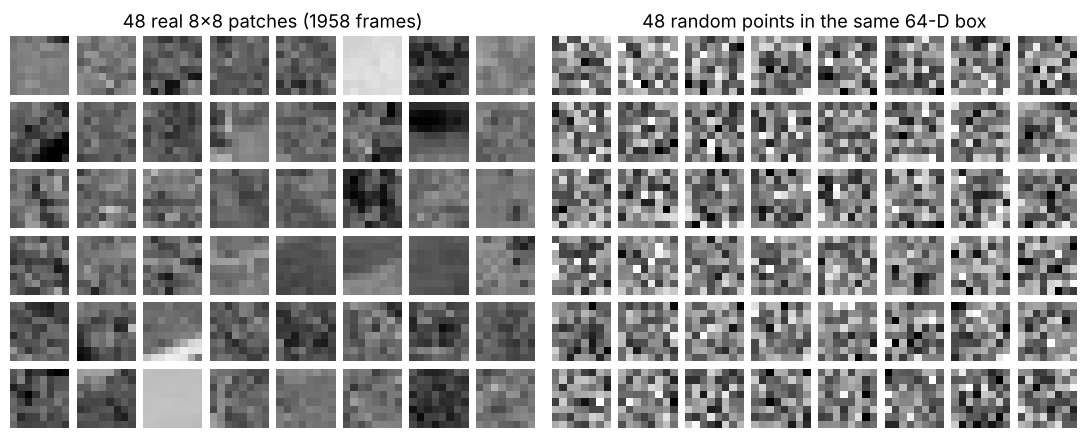

correlation of pixel (0,0) with its right neighbour (0,1):  real 0.900   noise 0.007


In [5]:
P = 8                                     # patch side; d = P*P = 64
rng = np.random.default_rng(0)

def sample_patches(img, n, rng, p=P, margin=40):
    h, w = img.shape
    ys = rng.integers(margin, h - margin - p, n)
    xs = rng.integers(margin, w - margin - p, n)
    return np.stack([img[y:y+p, x:x+p].ravel() for y, x in zip(ys, xs)]).astype(np.float64)

X = np.vstack([sample_patches(cv2.imread(f, 0), 3000, rng) for f in TRAIN])
n, d = X.shape
print(f"X: n = {n:,} patches  x  d = {d} pixels")

# Same overall mean and spread, but every pixel independent.
NOISE = rng.normal(X.mean(), X.std(), size=X.shape).clip(0, 255)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(tiles(X[:48], (P, P), 8, scale=(0, 255)), cmap="gray", vmin=0, vmax=1)
axes[0].set_title("48 real 8x8 patches (1958 frames)")
axes[1].imshow(tiles(NOISE[:48], (P, P), 8, scale=(0, 255)), cmap="gray", vmin=0, vmax=1)
axes[1].set_title("48 random points in the same 64-D box")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

# Neighbouring pixels inside a patch move together; in the noise they do not.
r_real = np.corrcoef(X[:, 0], X[:, 1])[0, 1]
r_noise = np.corrcoef(NOISE[:, 0], NOISE[:, 1])[0, 1]
print(f"correlation of pixel (0,0) with its right neighbour (0,1):  real {r_real:.3f}   noise {r_noise:.3f}")

---
## 2 · PCA in two dimensions: neighbouring pixels

Start with the smallest interesting case, $d = 2$. Take every pixel of frame 16046-19 and its
right-hand neighbour: about 950,000 points $(I(x,y),\ I(x{+}1,y))$. Because neighbours are
similar, the cloud is a long thin ellipse along the diagonal.

PCA asks: **which direction does the cloud vary most along?** Centre the data, form the
$2\times2$ covariance matrix $C$, and take its eigenvectors.

In [6]:
I = A.astype(np.float64)
X2 = np.c_[I[:, :-1].ravel(), I[:, 1:].ravel()]          # (n, 2): pixel, right neighbour
mu2 = X2.mean(axis=0)
X2c = X2 - mu2
C2 = X2c.T @ X2c / (len(X2) - 1)                          # 2x2 covariance
lam2, V2 = np.linalg.eigh(C2)                             # eigh: ascending order
lam2, V2 = lam2[::-1], V2[:, ::-1]                        # largest first
V2 = V2 * np.sign(V2[0])                                  # sign is arbitrary; make first entries +

print(f"n = {len(X2):,} pairs,  mean = ({mu2[0]:.1f}, {mu2[1]:.1f}),  correlation = {np.corrcoef(X2.T)[0,1]:.3f}")
print("C =\n", np.round(C2, 1))
print(f"eigenvalues  λ1 = {lam2[0]:.0f},  λ2 = {lam2[1]:.0f}")
print(f"explained variance:  PC1 {lam2[0]/lam2.sum():.1%},  PC2 {lam2[1]/lam2.sum():.1%}")
print(f"PC1 = ({V2[0,0]:+.4f}, {V2[1,0]:+.4f})   PC2 = ({V2[0,1]:+.4f}, {V2[1,1]:+.4f})   1/√2 = {1/np.sqrt(2):.4f}")

n = 952,000 pairs,  mean = (121.9, 121.9),  correlation = 0.888
C =
 [[2733.2 2428.5]
 [2428.5 2733.5]]
eigenvalues  λ1 = 5162,  λ2 = 305
explained variance:  PC1 94.4%,  PC2 5.6%
PC1 = (+0.7071, +0.7071)   PC2 = (+0.7071, -0.7071)   1/√2 = 0.7071


The two directions are, to four decimals, $(1, 1)/\sqrt2$ and $(1, -1)/\sqrt2$.

* **PC1** = $(I_0 + I_1)/\sqrt2$ — a scaled **average** of the two pixels: L3's box filter.
* **PC2** = $(I_0 - I_1)/\sqrt2$ — a scaled **difference**: L4's horizontal derivative.

PCA has rediscovered smoothing and edge detection from the data alone. Projecting every pair
onto each direction gives two new images.

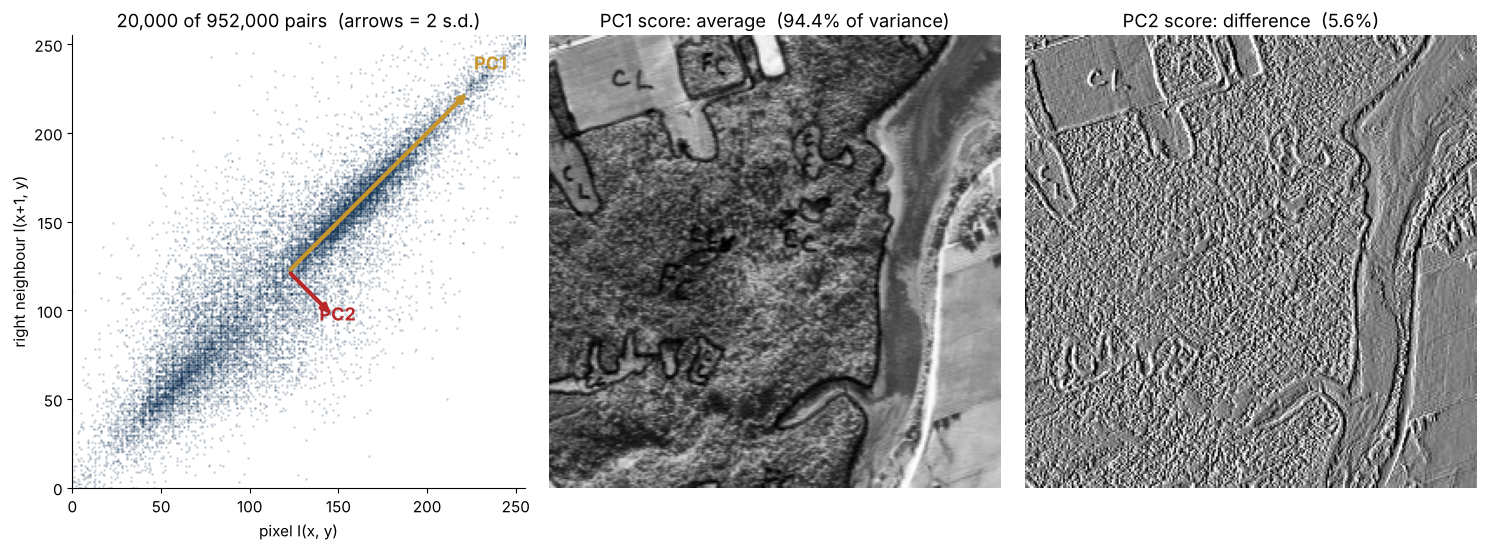

In [7]:
Z2 = X2c @ V2                                             # scores on PC1, PC2
h, w = I.shape
pc1_img = Z2[:, 0].reshape(h, w - 1)
pc2_img = Z2[:, 1].reshape(h, w - 1)

fig = plt.figure(figsize=(15, 5.2))
ax = fig.add_subplot(1, 3, 1)
sub = rng.choice(len(X2), 20000, replace=False)
ax.scatter(X2[sub, 0], X2[sub, 1], s=1, alpha=0.15, color=NAVY, rasterized=True)
for k, (col, name) in enumerate([(GOLD, "PC1"), (RED, "PC2")]):
    v = V2[:, k] * 2 * np.sqrt(lam2[k])
    ax.annotate("", mu2 + v, mu2, arrowprops=dict(arrowstyle="-|>", color=col, lw=3))
    ax.text(*(mu2 + v * 1.12), name, color=col, fontsize=13, fontweight="bold", ha="center")
ax.set_xlabel("pixel I(x, y)"); ax.set_ylabel("right neighbour I(x+1, y)")
ax.set_title(f"20,000 of {len(X2):,} pairs  (arrows = 2 s.d.)"); ax.set_aspect("equal")
ax.set_xlim(0, 255); ax.set_ylim(0, 255)
crop = (slice(300, 560), slice(380, 640))
ax = fig.add_subplot(1, 3, 2); ax.imshow(pc1_img[crop], cmap="gray")
ax.set_title(f"PC1 score: average  ({lam2[0]/lam2.sum():.1%} of variance)"); ax.axis("off")
ax = fig.add_subplot(1, 3, 3); ax.imshow(pc2_img[crop], cmap="gray", vmin=-40, vmax=40)
ax.set_title(f"PC2 score: difference  ({lam2[1]/lam2.sum():.1%})"); ax.axis("off")
plt.tight_layout(); plt.show()

### 2.1 — Two views of the same direction

PC1 is the direction of **maximum variance** of the projections. It is also the line that
**minimises the squared distance** from the points to the line. These are the same thing, by
Pythagoras: for each centred point, $\|x\|^2 = (\text{projection})^2 + (\text{residual})^2$.
The left side does not depend on the direction, so making the projections as large as possible
makes the residuals as small as possible.

Check it numerically for every unit direction $u(\theta)$.

max |projection² + residual² − total| over all directions: 2.73e-12
best direction by variance: 45.0°,  by residual: 45.0°  (45° = the diagonal)


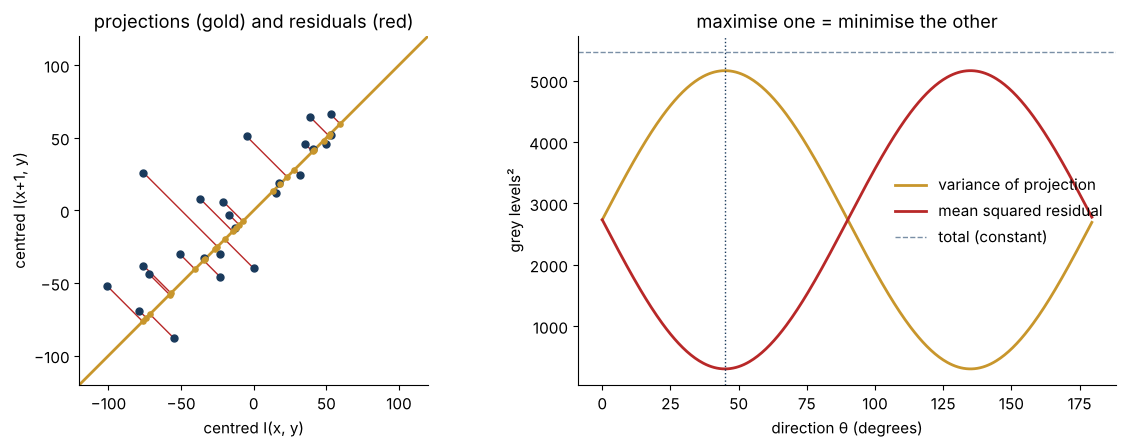

In [8]:
thetas = np.radians(np.arange(0, 180, 0.5))
total = (X2c ** 2).sum(axis=1).mean()
proj_var, resid = [], []
for t in thetas:
    u = np.array([np.cos(t), np.sin(t)])
    z = X2c @ u
    proj_var.append((z ** 2).mean())
    resid.append(((X2c - np.outer(z, u)) ** 2).sum(axis=1).mean())
proj_var, resid = np.array(proj_var), np.array(resid)
print(f"max |projection² + residual² − total| over all directions: {np.abs(proj_var + resid - total).max():.2e}")
print(f"best direction by variance: {np.degrees(thetas[proj_var.argmax()]):.1f}°,  "
      f"by residual: {np.degrees(thetas[resid.argmin()]):.1f}°  (45° = the diagonal)")

# A picture of it, on 25 points.
pts = X2c[rng.choice(len(X2c), 25, replace=False)] / 1.0
u = V2[:, 0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ax = axes[0]
ax.axline((0, 0), slope=u[1]/u[0], color=GOLD, lw=2, label="PC1")
proj = np.outer(pts @ u, u)
for p_, q_ in zip(pts, proj):
    ax.plot([p_[0], q_[0]], [p_[1], q_[1]], color=RED, lw=1)
ax.scatter(*pts.T, color=NAVY, zorder=3, s=25); ax.scatter(*proj.T, color=GOLD, zorder=3, s=14)
ax.set_aspect("equal"); ax.set_xlim(-120, 120); ax.set_ylim(-120, 120)
ax.set_title("projections (gold) and residuals (red)"); ax.set_xlabel("centred I(x, y)"); ax.set_ylabel("centred I(x+1, y)")
ax = axes[1]
ax.plot(np.degrees(thetas), proj_var, color=GOLD, lw=2, label="variance of projection")
ax.plot(np.degrees(thetas), resid, color=RED, lw=2, label="mean squared residual")
ax.axhline(total, color=GREY, ls="--", lw=1, label="total (constant)")
ax.axvline(45, color=NAVY, lw=1, ls=":")
ax.set_xlabel("direction θ (degrees)"); ax.set_ylabel("grey levels²"); ax.legend(frameon=False)
ax.set_title("maximise one = minimise the other")
plt.tight_layout(); plt.show()

---
## 3 · The recipe, and the notation

The same steps work in any dimension. With $n$ examples of $d$ features (here 54,000 patches
of 64 pixels), we use the notation of Assignment 1:

| symbol | shape | what it is |
|---|---|---|
| $X$ | $n \times d$ | data, one example per **row** |
| $\mu$ | $1 \times d$ | mean of the rows — the "mean patch" |
| $W$ | $k \times d$ | the $k$ principal components, one per **row**, unit length, orthogonal |
| $Z = (X-\mu)\,W^\top$ | $n \times k$ | the new, short description of each example ("scores") |
| $\hat X = Z\,W + \mu$ | $n \times d$ | the reconstruction from $k$ numbers per example |

The rows of $W$ are the top-$k$ eigenvectors of the covariance $C = (X-\mu)^\top (X-\mu) / (n-1)$
($d \times d$), and the eigenvalue $\lambda_j$ is the variance of the data along component $j$.

In [9]:
mu = X.mean(axis=0)                     # (64,)
Xc = X - mu
t0 = time.perf_counter()
C = Xc.T @ Xc / (n - 1)                 # (64, 64)
lam_eig, V_eig = np.linalg.eigh(C)
lam_eig, V_eig = lam_eig[::-1], V_eig[:, ::-1]
t_eig = time.perf_counter() - t0
print(f"C is {C.shape}; eigendecomposition in {t_eig*1e3:.1f} ms")
print(f"total variance = trace(C) = {np.trace(C):,.0f} = sum of eigenvalues = {lam_eig.sum():,.0f}")
print(f"first five eigenvalues: {np.round(lam_eig[:5]).astype(int)}")

C is (64, 64); eigendecomposition in 9.2 ms
total variance = trace(C) = 195,480 = sum of eigenvalues = 195,480
first five eigenvalues: [150946   7096   5835   2870   2291]


---
## 4 · The SVD

Any $n\times d$ matrix factors as $X_c = U\,\Sigma\,V^\top$:
$U$ ($n\times d$) and $V$ ($d \times d$) have orthonormal columns, and $\Sigma$ is diagonal with
$\sigma_1 \ge \sigma_2 \ge \dots \ge 0$. Substitute into the covariance:

$$C = \frac{X_c^\top X_c}{n-1} = V\,\frac{\Sigma^2}{n-1}\,V^\top$$

So the **rows of $V^\top$ are the principal components**, $\lambda_j = \sigma_j^2/(n-1)$, and the
scores are $Z = X_c V = U\Sigma$. We never have to form $C$.

In [10]:
t0 = time.perf_counter()
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)       # U (n, 64), S (64,), Vt (64, 64)
t_svd = time.perf_counter() - t0
lam = S ** 2 / (n - 1)
print(f"SVD of the {n:,} x {d} matrix in {t_svd*1e3:.0f} ms")
print(f"max |σ²/(n−1) − λ| = {np.abs(lam - lam_eig).max():.2e}")
# Components agree up to sign: compare |cosines|.
cos = np.abs(np.sum(Vt * V_eig.T, axis=1))
print(f"|cos| between SVD and eig components: min over 64 = {cos.min():.6f}")
# Scores two ways.
Z_a, Z_b = Xc @ Vt[:3].T, U[:, :3] * S[:3]
print(f"max |X_c Vᵀ − UΣ| (first 3 scores) = {np.abs(Z_a - Z_b).max():.2e}")

SVD of the 54,000 x 64 matrix in 201 ms
max |σ²/(n−1) − λ| = 2.91e-11
|cos| between SVD and eig components: min over 64 = 1.000000
max |X_c Vᵀ − UΣ| (first 3 scores) = 5.23e-11


**Why prefer the SVD?** Forming $X^\top X$ squares the condition number: directions with small
variance get lost in rounding before the eigensolver sees them. The SVD works on $X_c$ directly.
In double precision on 64-D patches you will not notice; with float32, huge $d$, or nearly
degenerate data (L11's fundamental matrix) you will.

Forming $C$ is also impossible when $d$ is large: for a 100×100 image, $C$ is
$10{,}000\times10{,}000$. The SVD of the $n\times d$ data matrix only needs $\min(n,d)$ components.

---
## 5 · Rank-$k$ approximation of one image

The SVD applies to *any* matrix — including a single grayscale image. Keeping the top $k$
terms gives $A_k = \sum_{j\le k} \sigma_j u_j v_j^\top$, and the **Eckart–Young theorem** says
no rank-$k$ matrix is closer to $A$ in squared error. The error is exactly the discarded
singular values: $\|A - A_k\|_F^2 = \sum_{j>k}\sigma_j^2$.

Storage: $k(m + n + 1)$ numbers instead of $mn$.

 k   storage   RMSE   Eckart–Young   PSNR
  1     0.4%   49.19      49.19      14.3 dB
  5     2.0%   39.37      39.37      16.2 dB
 20     7.8%   29.11      29.11      18.8 dB
 50    19.6%   21.26      21.26      21.6 dB
100    39.1%   14.80      14.80      24.7 dB
200    78.2%    7.97       7.97      30.1 dB


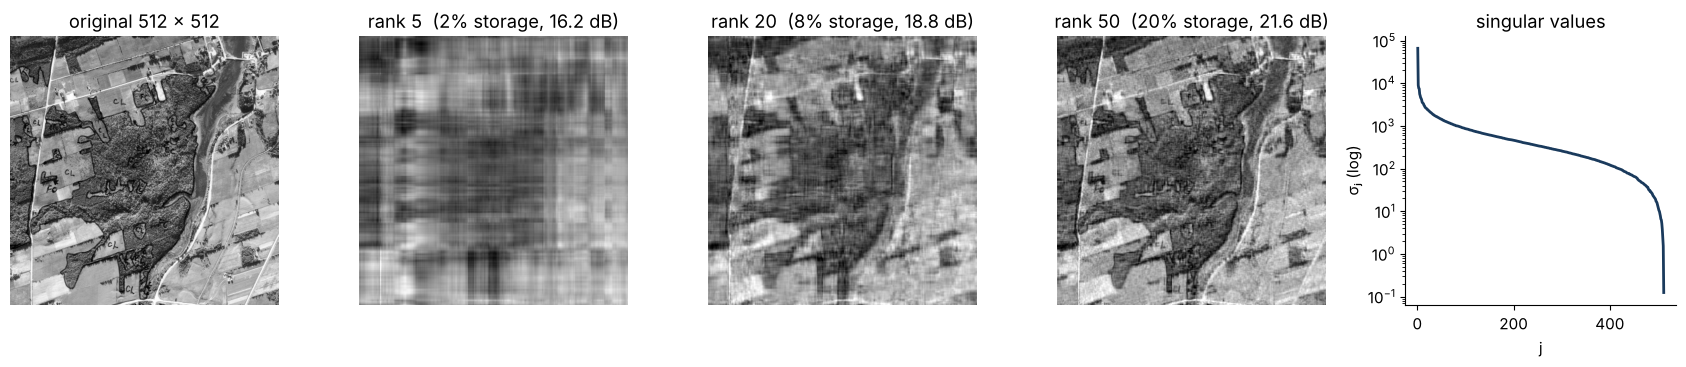

In [11]:
crop = A[200:712, 220:732].astype(np.float64)            # 512 x 512 centre of frame 16046-19
m_, n_ = crop.shape
Ui, Si, Vti = np.linalg.svd(crop, full_matrices=False)
rows = []
for k in [1, 5, 20, 50, 100, 200]:
    Ak = (Ui[:, :k] * Si[:k]) @ Vti[:k]
    rmse = np.sqrt(np.mean((Ak - crop) ** 2))
    pred = np.sqrt((Si[k:] ** 2).sum() / (m_ * n_))
    rows.append((k, k * (m_ + n_ + 1) / (m_ * n_), rmse, pred, psnr(crop, Ak)))
print(" k   storage   RMSE   Eckart–Young   PSNR")
for k, st, e, pr, p_ in rows:
    print(f"{k:3d}   {st:6.1%}   {e:5.2f}      {pr:5.2f}      {p_:4.1f} dB")

fig, axes = plt.subplots(1, 5, figsize=(17, 3.8))
axes[0].imshow(crop, cmap="gray", vmin=0, vmax=255); axes[0].set_title("original 512 x 512")
for ax, k in zip(axes[1:4], [5, 20, 50]):
    Ak = (Ui[:, :k] * Si[:k]) @ Vti[:k]
    ax.imshow(np.clip(Ak, 0, 255), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"rank {k}  ({k*(m_+n_+1)/(m_*n_):.0%} storage, {psnr(crop, Ak):.1f} dB)")
for ax in axes[:4]: ax.axis("off")
axes[4].semilogy(np.arange(1, len(Si) + 1), Si, color=NAVY, lw=2)
axes[4].set_xlabel("j"); axes[4].set_ylabel("σⱼ (log)"); axes[4].set_title("singular values")
plt.tight_layout(); plt.show()

The first singular value is huge (it carries the average brightness); after that the spectrum
falls slowly. Aerial texture — fields, hedgerows, film grain — is not low-rank as a whole
image. Section 8 shows that PCA on small *patches* does much better at the same storage:
images are locally simple, not globally simple.

---
## 6 · The other end of the SVD: L8's DLT

PCA keeps the **largest** singular values: the directions the data varies most along. L8's
direct linear transform used the **smallest**: it stacked two rows per match into $A$
($2N\times 9$) and took the last row of $V^\top$ — the direction $h$ along which $A$ is
*smallest*, minimising $\|Ah\|$ with $\|h\| = 1$.

Same decomposition, opposite ends. Rebuild it on six points that `H_REF` maps exactly, plus
half a pixel of noise.

In [12]:
H_REF = np.array([[ 0.98700935, -0.00873884, -390.04915793],      # frame 19 -> 20 (AL5, L8)
                  [ 0.00098735,  1.01974419,  -25.81833349],
                  [-0.00000007,  0.00002919,    1.        ]])

def project(p, H):
    q = np.c_[p, np.ones(len(p))] @ H.T
    return q[:, :2] / q[:, 2:]

p6 = np.array([[500, 100], [900, 150], [450, 500], [880, 520], [520, 900], [920, 880]], float)
q6 = project(p6, H_REF) + np.random.default_rng(1).normal(0, 0.5, (6, 2))
rows_ = []
for (x, y), (u_, v_) in zip(p6, q6):
    rows_.append([-x, -y, -1, 0, 0, 0, u_*x, u_*y, u_])
    rows_.append([0, 0, 0, -x, -y, -1, v_*x, v_*y, v_])
Adlt = np.array(rows_)
_, Sd, Vtd = np.linalg.svd(Adlt)
Hd = Vtd[-1].reshape(3, 3); Hd /= Hd[2, 2]
np.set_printoptions(precision=3, suppress=False)
print("singular values of A (12 x 9):\n", Sd)
print(f"\nsmallest / largest = {Sd[-1]/Sd[0]:.1e}")
print(f"corner error of H from the last row of Vᵀ: "
      f"{np.abs(project(np.array([[0,0],[952,0],[0,999],[952,999]]), Hd) - project(np.array([[0,0],[952,0],[0,999],[952,999]]), H_REF)).max():.2f} px")
np.set_printoptions()

singular values of A (12 x 9):
 [1.749e+06 4.011e+05 2.087e+03 1.038e+03 5.118e+02 3.182e+02 1.260e+02
 3.801e-01 1.148e-03]

smallest / largest = 6.6e-10
corner error of H from the last row of Vᵀ: 2.69 px


The last singular value is about 300 times smaller than the one before it: $A$ has (almost)
a null direction, and that direction is $H$. The corner error of a few pixels is L8's lesson
again — six noisy, unnormalised points; RANSAC's refit on hundreds of inliers fixes it.

| | keep the **largest** $\sigma$ | keep the **smallest** $\sigma$ |
|---|---|---|
| question | where does the data vary most? | what direction is the data (nearly) zero along? |
| used for | PCA, compression, eigenfaces | DLT for $H$ (L8), fundamental matrix (L11), line fitting |

---
## 7 · Eigen-patches and explained variance

Back to the 54,000 patches. Each principal component is a 64-vector, so we can reshape it to
8×8 and **look at it**. These are the patterns the 1958 photographs are built from, ordered by
how much variance each explains.

explained variance of the first 8 components (%): [77.22  3.63  2.98  1.47  1.17  1.04  0.8   0.66]
mean patch μ: almost flat, 125–125 grey levels


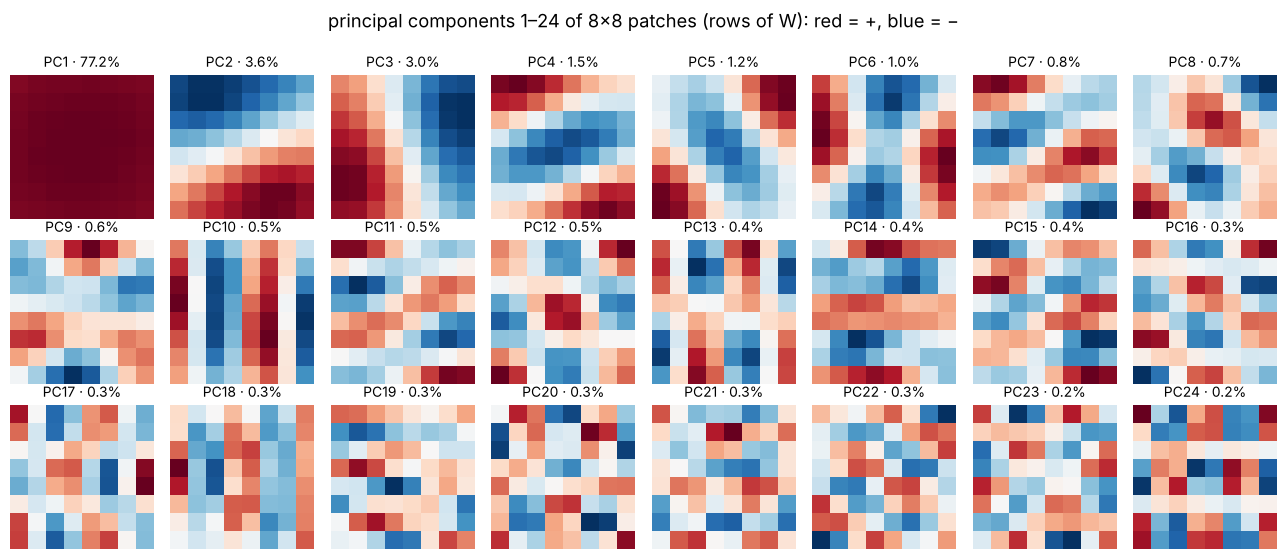

In [13]:
ev = lam / lam.sum()
cum = np.cumsum(ev)
print("explained variance of the first 8 components (%):", np.round(100 * ev[:8], 2))

Vt *= np.sign(Vt.sum(axis=1, keepdims=True) + 1e-9)        # cosmetic: signs are arbitrary
print(f"mean patch μ: almost flat, {mu.min():.0f}–{mu.max():.0f} grey levels")
fig, axes = plt.subplots(3, 8, figsize=(13, 5.6))
for j, ax in enumerate(axes.ravel()):
    v = Vt[j].reshape(P, P)
    ax.imshow(v / np.abs(v).max(), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_title(f"PC{j+1} · {100*ev[j]:.1f}%", fontsize=10); ax.axis("off")
plt.suptitle("principal components 1–24 of 8x8 patches (rows of W): red = +, blue = −", y=0.995)
plt.tight_layout(); plt.show()

Read the first few:

* **PC1** is almost flat — the patch's overall brightness (77% of all the variance: bright field vs dark woodlot).
* **PC2, PC3** are smooth ramps — horizontal and vertical gradients: L4's Sobel filters.
* **Next** come second derivatives and checkerboards — finer and finer detail, like the
  JPEG/DCT basis (JPEG uses exactly 8×8 blocks).

Nobody told PCA about filters. It found them because they are the most efficient way to
describe photographs of the world.

variance kept   k (1958 patches)   k (noise)
     80%              2               51
     90%             10               58
     95%             26               61
     99%             53               64


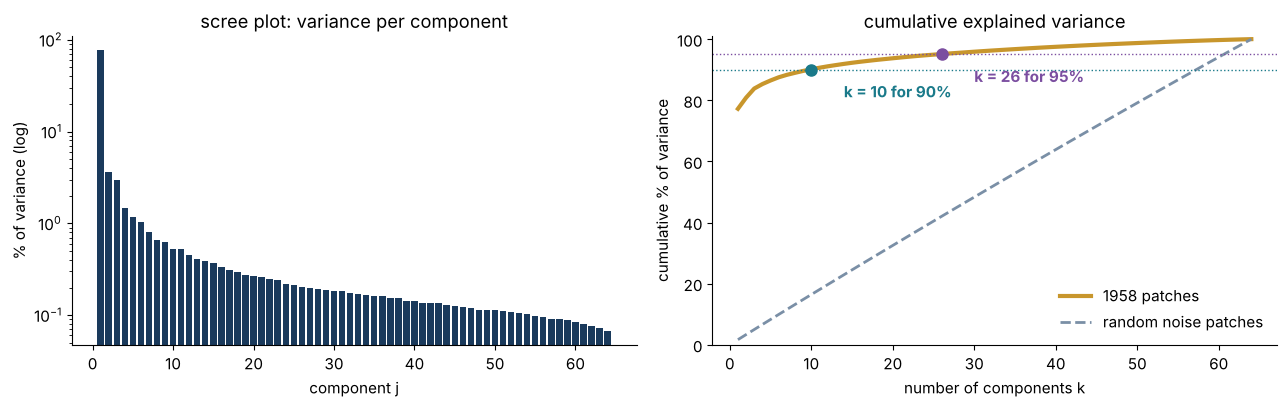

In [14]:
# How many components do we need?  Real patches vs noise patches.
Sn = np.linalg.svd(NOISE - NOISE.mean(axis=0), compute_uv=False)
cum_noise = np.cumsum(Sn ** 2) / (Sn ** 2).sum()
k_for = {t: int(np.searchsorted(cum, t) + 1) for t in (0.8, 0.9, 0.95, 0.99)}
k_for_noise = {t: int(np.searchsorted(cum_noise, t) + 1) for t in (0.8, 0.9, 0.95, 0.99)}
print("variance kept   k (1958 patches)   k (noise)")
for t in k_for:
    print(f"     {t:.0%}            {k_for[t]:3d}              {k_for_noise[t]:3d}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
j = np.arange(1, d + 1)
axes[0].bar(j, 100 * ev, color=NAVY, width=0.8)
axes[0].set_yscale("log"); axes[0].set_xlabel("component j"); axes[0].set_ylabel("% of variance (log)")
axes[0].set_title("scree plot: variance per component")
axes[1].plot(j, 100 * cum, color=GOLD, lw=3, label="1958 patches")
axes[1].plot(j, 100 * cum_noise, color=GREY, lw=2, ls="--", label="random noise patches")
for t, col in [(0.9, TEAL), (0.95, PURPLE)]:
    axes[1].axhline(100 * t, color=col, lw=1, ls=":")
    axes[1].plot(k_for[t], 100 * t, "o", color=col, ms=8)
    axes[1].annotate(f"k = {k_for[t]} for {t:.0%}", (k_for[t], 100 * t), (k_for[t] + 4, 100 * t - 9),
                     color=col, fontsize=11, fontweight="bold")
axes[1].set_xlabel("number of components k"); axes[1].set_ylabel("cumulative % of variance")
axes[1].set_ylim(0, 101); axes[1].legend(frameon=False, loc="lower right")
axes[1].set_title("cumulative explained variance")
plt.tight_layout(); plt.show()

---
## 8 · Reconstruction error and choosing $k$

Project onto the first $k$ components and back: $Z = (X - \mu)W^\top$, $\hat X = ZW + \mu$.
On the **training** data the mean squared error per pixel is exactly the variance we threw
away, $\frac{1}{d}\sum_{j>k}\lambda_j$. On the held-out frame it should be close — if it is
much worse, the components do not generalise.

  k   train RMSE (=discarded λ)   test RMSE on 16046-19   test PSNR
  1           26.38                   29.16            18.8 dB
  2           24.19                   26.03            19.8 dB
  4           21.19                   22.16            21.2 dB
  8           18.35                   18.57            22.8 dB
 16           15.03                   14.60            24.8 dB
 32           10.71                    9.97            28.2 dB
 64            0.00                    0.00           310.7 dB


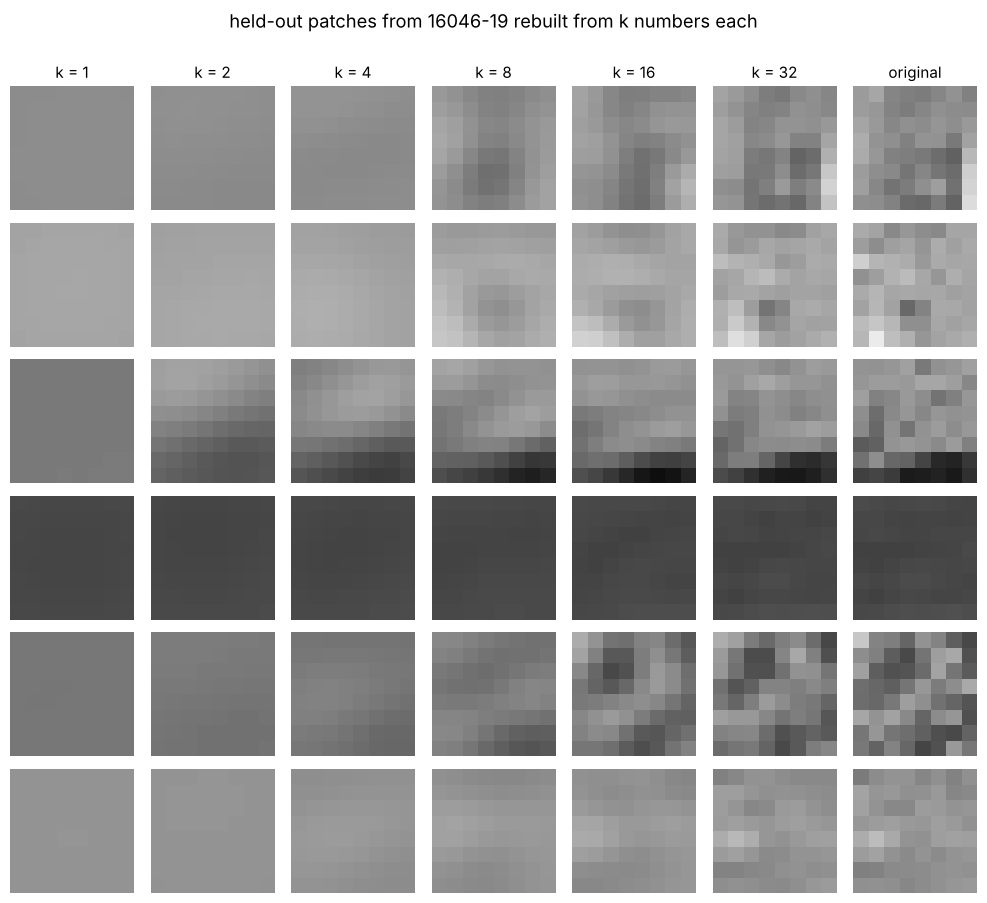

In [15]:
T = sample_patches(A, 5000, np.random.default_rng(2))              # held-out frame 16046-19
print("  k   train RMSE (=discarded λ)   test RMSE on 16046-19   test PSNR")
recon_rows = []
for k in [1, 2, 4, 8, 16, 32, 64]:
    W = Vt[:k]                                        # (k, 64)
    Zt = (T - mu) @ W.T                                # (5000, k)
    That = Zt @ W + mu                                 # (5000, 64)
    pred = np.sqrt(lam[k:].sum() * (n - 1) / n / d) if k < d else 0.0
    rmse = np.sqrt(np.mean((That - T) ** 2))
    recon_rows.append((k, pred, rmse))
    print(f"{k:3d}          {pred:6.2f}                  {rmse:6.2f}           {psnr(T, That):5.1f} dB")

idx = [3, 17, 41, 88, 130, 205]
fig, axes = plt.subplots(len(idx), 7, figsize=(10, 9))
for r, i in enumerate(idx):
    for c, k in enumerate([1, 2, 4, 8, 16, 32, None]):
        ax = axes[r, c]
        if k is None:
            ax.imshow(T[i].reshape(P, P), cmap="gray", vmin=0, vmax=255)
            if r == 0: ax.set_title("original", fontsize=11)
        else:
            W = Vt[:k]; rec = ((T[i] - mu) @ W.T) @ W + mu
            ax.imshow(np.clip(rec, 0, 255).reshape(P, P), cmap="gray", vmin=0, vmax=255)
            if r == 0: ax.set_title(f"k = {k}", fontsize=11)
        ax.axis("off")
plt.suptitle("held-out patches from 16046-19 rebuilt from k numbers each", y=1.0)
plt.tight_layout(); plt.show()

### 8.1 — A whole picture, patch by patch, vs the whole-image SVD

Cut the same 512×512 crop from section 5 into 4,096 non-overlapping 8×8 tiles, keep $k$
scores per tile, and rebuild. Storage is $k/64$ of the original (plus the 64×$k$ basis and the
mean, which are shared). Compare with the rank-$r$ SVD of section 5 at the **same storage**.

storage   patch PCA (k per tile)   whole-image SVD (rank r)
  6.2%     k =  4: 20.4 dB          r =  16: 18.4 dB
 12.5%     k =  8: 22.0 dB          r =  32: 20.1 dB
 25.0%     k = 16: 24.2 dB          r =  64: 22.6 dB


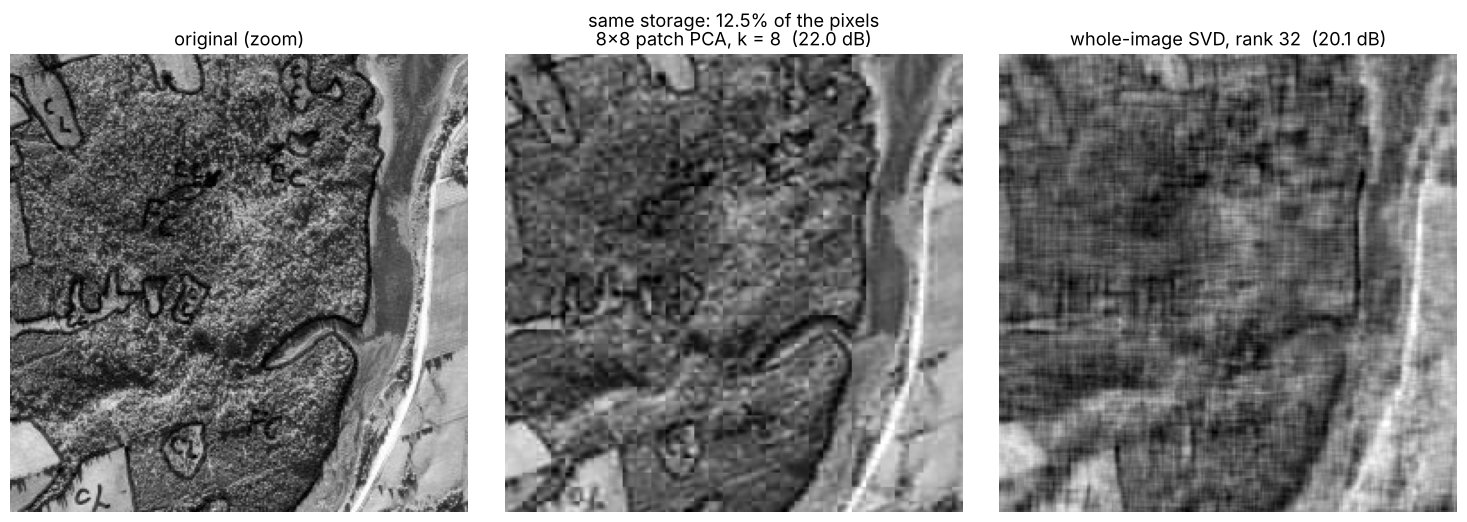

In [16]:
def tile_pca(img, k):
    h_, w_ = img.shape
    t = img.reshape(h_ // P, P, w_ // P, P).transpose(0, 2, 1, 3).reshape(-1, P * P)
    W = Vt[:k]
    rec = ((t - mu) @ W.T) @ W + mu
    return rec.reshape(h_ // P, w_ // P, P, P).transpose(0, 2, 1, 3).reshape(h_, w_)

cmp_rows = []
for k in [4, 8, 16]:
    st = k / 64
    r = int(round(st * m_ * n_ / (m_ + n_ + 1)))
    Ar = (Ui[:, :r] * Si[:r]) @ Vti[:r]
    tp = tile_pca(crop, k)
    cmp_rows.append((k, st, r, psnr(crop, tp), psnr(crop, Ar)))
print("storage   patch PCA (k per tile)   whole-image SVD (rank r)")
for k, st, r, a_, b_ in cmp_rows:
    print(f" {st:5.1%}     k = {k:2d}: {a_:4.1f} dB          r = {r:3d}: {b_:4.1f} dB")

k = 8; st = k / 64; r = int(round(st * m_ * n_ / (m_ + n_ + 1)))
fig, axes = plt.subplots(1, 3, figsize=(15, 5.3))
zoom = (slice(150, 406), slice(150, 406))
axes[0].imshow(crop[zoom], cmap="gray", vmin=0, vmax=255); axes[0].set_title("original (zoom)")
axes[1].imshow(np.clip(tile_pca(crop, k), 0, 255)[zoom], cmap="gray", vmin=0, vmax=255)
axes[1].set_title(f"8x8 patch PCA, k = {k}  ({psnr(crop, tile_pca(crop, k)):.1f} dB)")
Ar = (Ui[:, :r] * Si[:r]) @ Vti[:r]
axes[2].imshow(np.clip(Ar, 0, 255)[zoom], cmap="gray", vmin=0, vmax=255)
axes[2].set_title(f"whole-image SVD, rank {r}  ({psnr(crop, Ar):.1f} dB)")
for ax in axes: ax.axis("off")
plt.suptitle(f"same storage: {st:.1%} of the pixels", y=0.98)
plt.tight_layout(); plt.show()

**Choosing $k$** has no single right answer. Common rules:

1. **A variance target** — 90%, 95%, 99% of the variance (section 7's table).
2. **The elbow** of the scree plot — where adding a component stops buying much.
3. **The task** — the smallest $k$ that keeps your downstream result (a match rate, a
   classifier's accuracy) as good as with all $d$. Section 11.2 does this for SIFT.

Rule 3 is the honest one. Variance is not the same as usefulness.

---
## 9 · Eigenfaces

Turk and Pentland (1991) applied exactly this to **aligned face photographs**. Each principal
component, reshaped to an image, looks like a ghostly face — an **eigenface** — and any face is
approximately the mean face plus a weighted sum of a few of them.

scikit-image ships a small set from the *Labeled Faces in the Wild* collection: 100 faces and
100 non-face patches, each 25×25 (so $d = 625$). Tiny, but enough to see the idea. Assignment 1
does the same on 100×100 animal faces.

We **normalise each image** to zero mean and unit standard deviation first — the same contrast
normalisation SIFT applies to its descriptor (L7) — so that "a face" does not depend on how
bright the photo was.

training faces (70, 625),  held-out faces 30,  non-faces 100


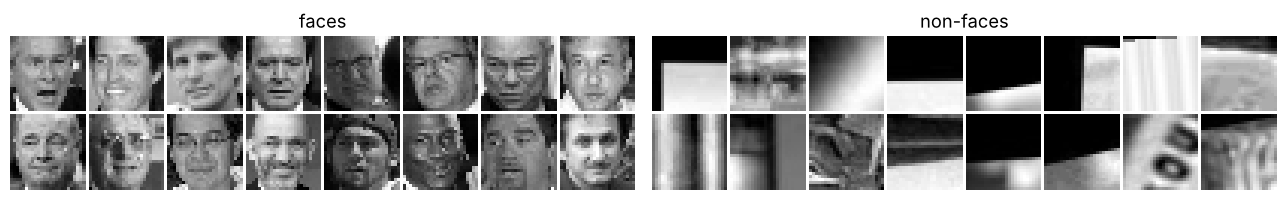

In [17]:
from skimage import data as skdata
L = skdata.lfw_subset()                       # (200, 25, 25), floats in [0, 1]; first 100 are faces
FS = (25, 25)
raw = L.reshape(len(L), -1)

def normalise(V):
    V = V - V.mean(axis=1, keepdims=True)
    return V / V.std(axis=1, keepdims=True)

Xf_all, Xnon = normalise(raw[:100]), normalise(raw[100:])
perm = np.random.default_rng(0).permutation(100)
tr, te = perm[:70], perm[70:]
Xf = Xf_all[tr]                               # 70 training faces; 30 held out
print(f"training faces {Xf.shape},  held-out faces {len(te)},  non-faces {len(Xnon)}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
axes[0].imshow(tiles(Xf_all[:16], FS, 8), cmap="gray"); axes[0].set_title("faces"); axes[0].axis("off")
axes[1].imshow(tiles(Xnon[:16], FS, 8), cmap="gray"); axes[1].set_title("non-faces"); axes[1].axis("off")
plt.tight_layout(); plt.show()

n = 70 faces, d = 625 pixels -> at most n − 1 = 69 non-zero components
explained variance of eigenfaces 1–6 (%): [18.1 10.1  7.6  6.1  5.1  4. ]
components for 50 / 80 / 90 / 95% of variance: [6, 23, 36, 48]


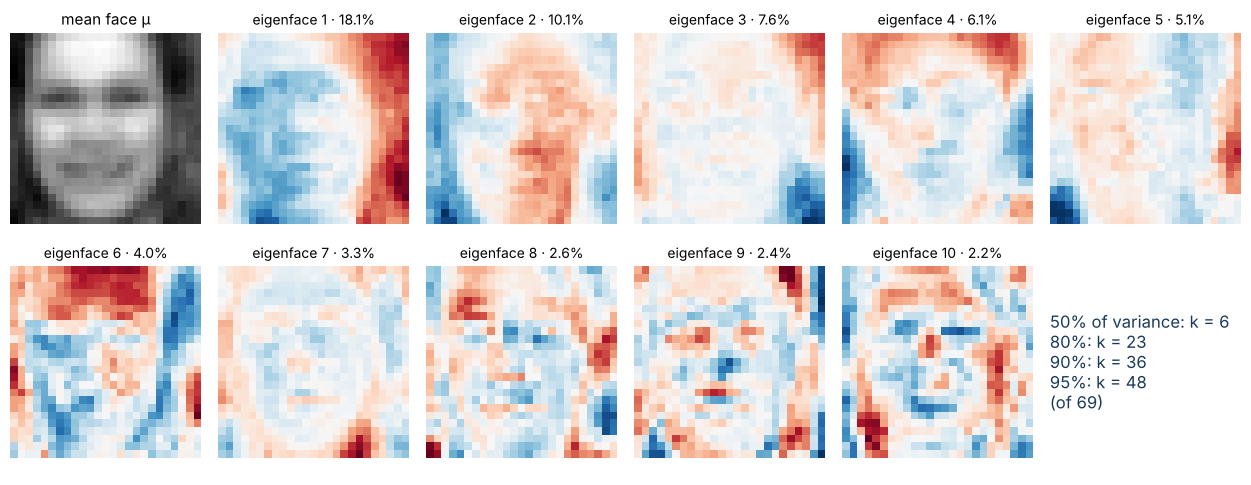

In [18]:
mu_f = Xf.mean(axis=0)
Uf, Sf, Vtf = np.linalg.svd(Xf - mu_f, full_matrices=False)     # Vtf: (70, 625)
lam_f = Sf ** 2 / (len(Xf) - 1)
cum_f = np.cumsum(lam_f) / lam_f.sum()
print(f"n = {len(Xf)} faces, d = {Xf.shape[1]} pixels -> at most n − 1 = {int((Sf > 1e-9).sum())} non-zero components")
print("explained variance of eigenfaces 1–6 (%):", np.round(100 * lam_f[:6] / lam_f.sum(), 1))
kf = {t: int(np.searchsorted(cum_f, t) + 1) for t in (0.5, 0.8, 0.9, 0.95)}
print("components for 50 / 80 / 90 / 95% of variance:", list(kf.values()))

fig, axes = plt.subplots(2, 6, figsize=(13, 5.0))
axes = axes.ravel()
axes[0].imshow(mu_f.reshape(FS), cmap="gray"); axes[0].set_title("mean face μ", fontsize=11)
for j in range(10):
    v = Vtf[j] * np.sign(Vtf[j].sum() + 1e-9)
    axes[j + 1].imshow(v.reshape(FS) / np.abs(v).max(), cmap="RdBu_r", vmin=-1, vmax=1)
    axes[j + 1].set_title(f"eigenface {j+1} · {100*lam_f[j]/lam_f.sum():.1f}%", fontsize=10)
axes[11].axis("off")
axes[11].text(0.0, 0.5, f"50% of variance: k = {kf[0.5]}\n80%: k = {kf[0.8]}\n90%: k = {kf[0.9]}\n95%: k = {kf[0.95]}\n(of 69)",
              fontsize=12, va="center", color=NAVY)
for ax in axes[:11]: ax.axis("off")
plt.tight_layout(); plt.show()

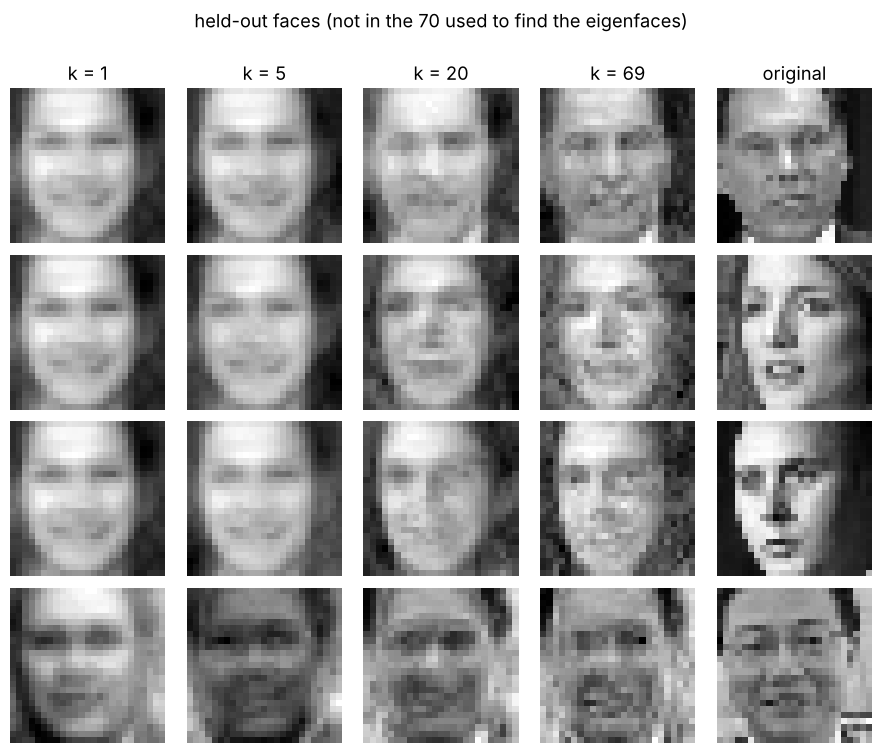

In [19]:
def recon_face(x, k):
    W = Vtf[:k]
    return ((x - mu_f) @ W.T) @ W + mu_f

ks = [1, 5, 20, 69]
show_idx = te[:4]
fig, axes = plt.subplots(len(show_idx), len(ks) + 1, figsize=(9, 7.5))
for r, i in enumerate(show_idx):
    x = Xf_all[i]
    for c, k in enumerate(ks):
        axes[r, c].imshow(recon_face(x, k).reshape(FS), cmap="gray")
        if r == 0: axes[r, c].set_title(f"k = {k}")
    axes[r, -1].imshow(x.reshape(FS), cmap="gray")
    if r == 0: axes[r, -1].set_title("original")
for ax in axes.ravel(): ax.axis("off")
plt.suptitle("held-out faces (not in the 70 used to find the eigenfaces)", y=1.0)
plt.tight_layout(); plt.show()

Even with all 69 components the held-out faces are not perfect: 70 training faces span at
most a 69-dimensional "face space", and a new face has some part that lies outside it. That
outside part is the next section's tool.

---
## 10 · Distance from face space

For any image $x$, the reconstruction $\hat x$ is the closest point *in face space*. The
residual $\|x - \hat x\|$ — the **distance from face space** — measures how un-face-like $x$
is. Turk and Pentland used it to *detect* faces: a small residual means "this looks like the
faces I learned from".

Score the 30 held-out faces and the 100 non-faces by their RMS residual and measure how well
it separates them (AUC: 1.0 = perfect, 0.5 = coin flip).

  k   median residual: faces   non-faces    AUC
  0                0.83       1.19     0.966
  1                0.80       1.16     0.956
  3                0.71       1.06     0.954
  5                0.66       0.95     0.954
 10                0.64       0.73     0.764
 20                0.59       0.65     0.708
 30                0.56       0.59     0.633
 50                0.52       0.54     0.605
 69                0.50       0.51     0.574


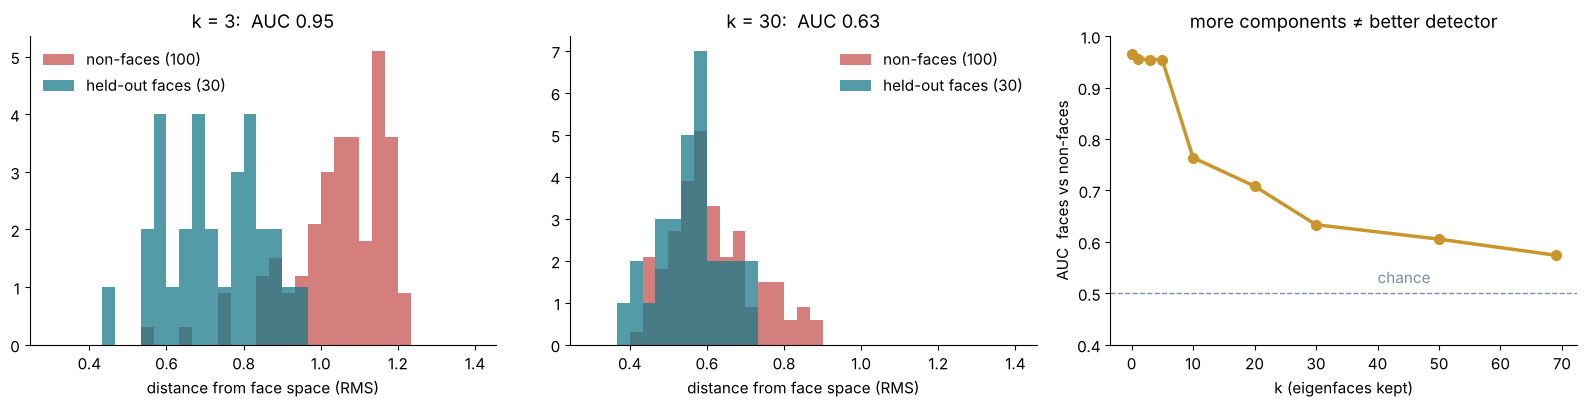

In [20]:
from sklearn.metrics import roc_auc_score

def dffs(V, k):
    R = V - recon_face(V, k) if k > 0 else V - mu_f
    return np.sqrt(np.mean(R ** 2, axis=1))

labels = np.r_[np.zeros(len(te)), np.ones(len(Xnon))]          # 1 = non-face
auc_rows = []
for k in [0, 1, 3, 5, 10, 20, 30, 50, 69]:
    ef, en = dffs(Xf_all[te], k), dffs(Xnon, k)
    auc_rows.append((k, np.median(ef), np.median(en), roc_auc_score(labels, np.r_[ef, en])))
print("  k   median residual: faces   non-faces    AUC")
for k, a_, b_, auc in auc_rows:
    print(f"{k:3d}                {a_:.2f}       {b_:.2f}     {auc:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, k in zip(axes[:2], [3, 30]):
    ef, en = dffs(Xf_all[te], k), dffs(Xnon, k)
    bins = np.linspace(0.3, 1.4, 34)
    ax.hist(en, bins, color=RED, alpha=0.6, label="non-faces (100)", density=True)
    ax.hist(ef, bins, color=TEAL, alpha=0.75, label="held-out faces (30)", density=True)
    auc = roc_auc_score(labels, np.r_[ef, en])
    ax.set_title(f"k = {k}:  AUC {auc:.2f}"); ax.set_xlabel("distance from face space (RMS)")
    ax.legend(frameon=False)
ks_ = [r[0] for r in auc_rows]; aucs = [r[3] for r in auc_rows]
axes[2].plot(ks_, aucs, "o-", color=GOLD, lw=2.5, ms=7)
axes[2].axhline(0.5, color=GREY, ls="--", lw=1); axes[2].text(40, 0.52, "chance", color=GREY)
axes[2].set_xlabel("k (eigenfaces kept)"); axes[2].set_ylabel("AUC  faces vs non-faces")
axes[2].set_ylim(0.4, 1.0); axes[2].set_title("more components ≠ better detector")
plt.tight_layout(); plt.show()

Two lessons:

* With a **few** components the residual separates faces from non-faces well. With **many**,
  face space grows to describe almost any 25×25 image — non-faces included — and the detector
  gets worse. With only 70 training faces, the later eigenfaces are mostly fitting those 70
  particular photos.
* $k = 0$ (distance to the mean face) already does well here, because the non-faces are
  arbitrary image patches. The eigenfaces earn their keep on harder negatives.

### 10.1 — Alignment matters

PCA compares pixel $i$ with pixel $i$. Shift a face sideways by a few pixels and it no longer
lines up with the mean face and the eigenfaces.

In [21]:
from scipy.ndimage import shift as nd_shift
k = 3
en = dffs(Xnon, k)
shift_rows = []
for s in [0, 1, 2, 3, 4, 6]:
    moved = np.stack([nd_shift(raw[i].reshape(FS), (0, s), mode="nearest").ravel() for i in te])
    e = dffs(normalise(moved), k)
    shift_rows.append((s, np.median(e), roc_auc_score(labels, np.r_[e, en])))
print(f"k = {k};  median non-face residual = {np.median(en):.2f}")
print("shift (px)   median face residual    AUC")
for s, e_, auc in shift_rows:
    print(f"    {s}              {e_:.2f}            {auc:.3f}")

k = 3;  median non-face residual = 1.06
shift (px)   median face residual    AUC
    0              0.71            0.954
    1              0.72            0.944
    2              0.76            0.924
    3              0.81            0.888
    4              0.86            0.852
    6              0.88            0.813


Each pixel of misalignment pushes the held-out faces further from face space, and the detector
loses accuracy: a 4-pixel shift (16% of the width) takes the AUC from 0.95 to 0.85. Eigenfaces need faces
**cropped, scaled and centred the same way** — which is why face pipelines detect and align
first (L15), and why later methods learn features that tolerate shifts (CNNs, L12–L13).

---
## 11 · PCA in your pipeline

### 11.1 — Colour bands (L2, project 7)

A colour pixel is a point in $\mathbb{R}^3$. Run PCA on all the pixels of the 2020
orthophoto.

1,934,528 pixels; channel correlations R–G 0.971, R–B 0.971, G–B 0.970
PC1: 98.14%  weights (R, G, B) = [0.68 0.56 0.48]
PC2:  1.08%  weights (R, G, B) = [ 0.71 -0.67 -0.21]
PC3:  0.78%  weights (R, G, B) = [ 0.2   0.48 -0.85]


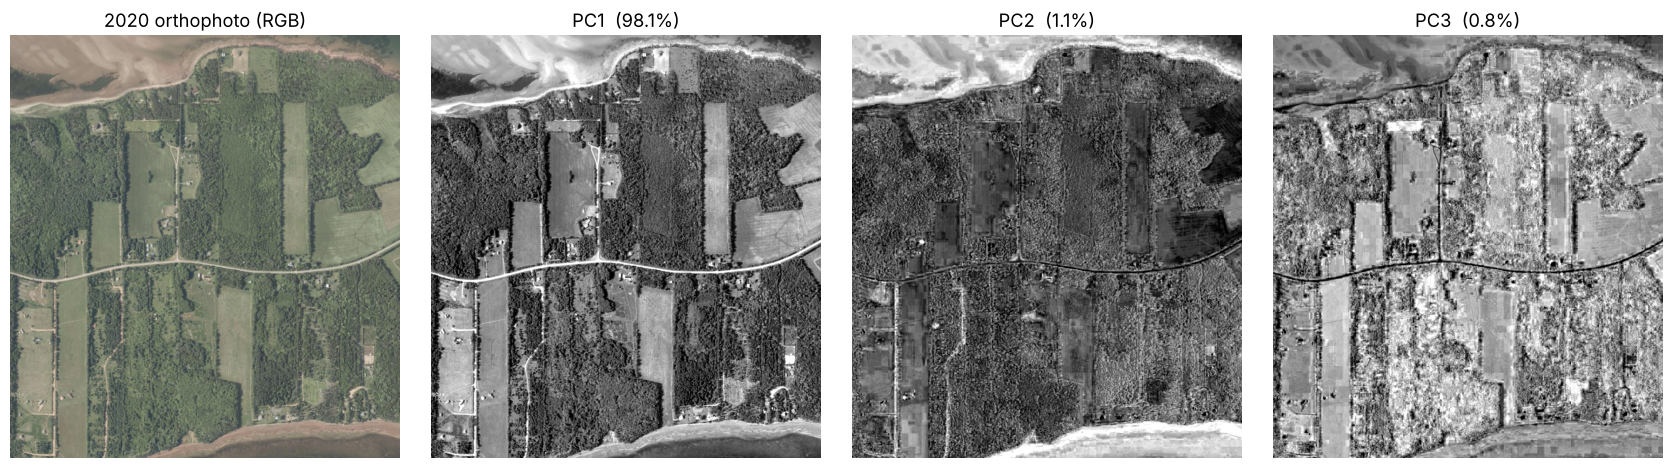

In [22]:
rgb = cv2.cvtColor(cv2.imread("eastern_pei_aerial_2020.png", cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
Xrgb = rgb.reshape(-1, 3).astype(np.float64)
mu_c = Xrgb.mean(axis=0)
Uc_, Sc, Vtc = np.linalg.svd(Xrgb - mu_c, full_matrices=False)
Vtc = Vtc * np.sign(Vtc[:, :1])                          # cosmetic: signs are arbitrary; make R weight +
lam_c = Sc ** 2 / (len(Xrgb) - 1)
print(f"{len(Xrgb):,} pixels; channel correlations R–G {np.corrcoef(Xrgb.T)[0,1]:.3f}, "
      f"R–B {np.corrcoef(Xrgb.T)[0,2]:.3f}, G–B {np.corrcoef(Xrgb.T)[1,2]:.3f}")
for j in range(3):
    print(f"PC{j+1}: {100*lam_c[j]/lam_c.sum():5.2f}%  weights (R, G, B) = {np.round(Vtc[j], 2)}")

Zc = ((Xrgb - mu_c) @ Vtc.T).reshape(rgb.shape)
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))
axes[0].imshow(rgb); axes[0].set_title("2020 orthophoto (RGB)")
for j in range(3):
    lo, hi = np.percentile(Zc[..., j], [1, 99])
    axes[j+1].imshow(Zc[..., j], cmap="gray", vmin=lo, vmax=hi)
    axes[j+1].set_title(f"PC{j+1}  ({100*lam_c[j]/lam_c.sum():.1f}%)")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

The three channels are 97% correlated, so PC1 — a near-equal mix of R, G and B — is
essentially "brightness" and carries 98% of the variance. That is why a grayscale photo still
looks like the scene.

The colour contrasts live in the other 2%. **PC2** (red against green) lights up PEI's red
sand and bare soil; **PC3** (green against blue) is bright on vegetation and dark on water,
and it is where fields and woodland differ most. For project 7 (deciduous vs coniferous,
colour 2020 vs grayscale history): the information your classifier wants may live in the 2%
of the variance that a grayscale scan never recorded. High variance is not the same as useful.

### 11.2 — Shorter SIFT descriptors (L7, L8)

A SIFT descriptor is a point in $\mathbb{R}^{128}$. Ke and Sukthankar's PCA-SIFT (2004) and
most large-scale retrieval systems shorten descriptors with PCA. Learn components from SIFT
descriptors of four *other* frames, project the L8 pair's descriptors to $k$ dimensions,
and redo L8's matching (brute force, ratio 0.8, correct = within 5 px of `H_REF`).
As a control, project onto $k$ **random** orthonormal directions instead.

11,654 and 11,239 keypoints on the pair; PCA learned from 39,511 descriptors of 4 other frames
components for 80 / 90 / 95% of descriptor variance: [35, 57, 78]



  k   variance kept   candidates   correct   precision   | random dirs: correct   match time
 128      100.0%        1,628      1,497      92.0%     |       1,497            1930 ms
  64      92.2%        1,702      1,499      88.1%     |       1,414            1104 ms
  32      78.7%        1,753      1,406      80.2%     |       1,259             792 ms
  16      62.3%        1,918      1,192      62.1%     |         893             422 ms
   8      45.4%        2,689        691      25.7%     |         405             518 ms

k = 32 -> MAGSAC: 1,342 inliers, alignment error 0.68 px vs H_REF


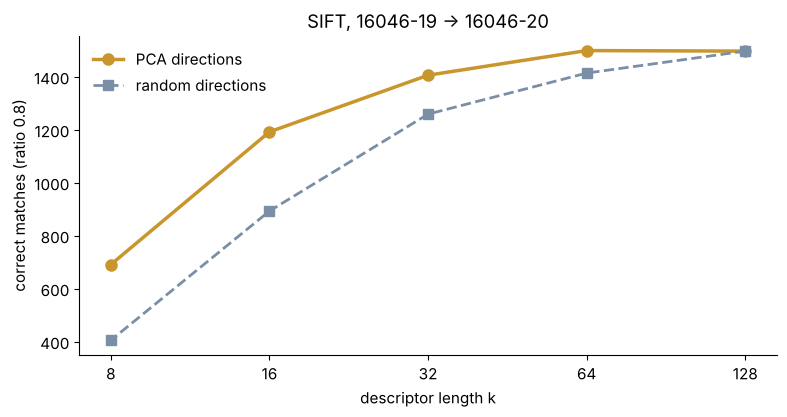

In [23]:
sift = cv2.SIFT_create()
B = cv2.imread(TEST[1], cv2.IMREAD_GRAYSCALE)
ka, da = sift.detectAndCompute(A, None)
kb, db = sift.detectAndCompute(B, None)
pa = np.float32([kp.pt for kp in ka]); pb = np.float32([kp.pt for kp in kb])
D = np.vstack([sift.detectAndCompute(cv2.imread(f, 0), None)[1]
               for f in ["frames/16046-17.jpg", "frames/16046-22.jpg",
                         "frames/16046-103.jpg", "frames/16100-72.jpg"]]).astype(np.float64)
mu_d = D.mean(axis=0)
_, Sd_, Vtd_ = np.linalg.svd(D - mu_d, full_matrices=False)
cum_d = np.cumsum(Sd_ ** 2) / (Sd_ ** 2).sum()
print(f"{len(ka):,} and {len(kb):,} keypoints on the pair; PCA learned from {len(D):,} descriptors of 4 other frames")
print("components for 80 / 90 / 95% of descriptor variance:",
      [int(np.searchsorted(cum_d, t) + 1) for t in (0.8, 0.9, 0.95)])

bf = cv2.BFMatcher(cv2.NORM_L2)
def match_score(fa, fb, r=0.8):
    fa, fb = np.ascontiguousarray(fa, np.float32), np.ascontiguousarray(fb, np.float32)
    t = time.perf_counter(); knn = bf.knnMatch(fa, fb, k=2); t = time.perf_counter() - t
    good = [m for m, m2 in knn if m.distance < r * m2.distance]
    p = pa[[g.queryIdx for g in good]]; q = pb[[g.trainIdx for g in good]]
    ok = np.linalg.norm(project(p, H_REF) - q, axis=1) < 5
    return len(good), int(ok.sum()), t, p, q

rng_q = np.random.default_rng(0)
sift_rows = []
for k in [128, 64, 32, 16, 8]:
    W = Vtd_[:k]
    kept, correct, t, p_k, q_k = match_score((da - mu_d) @ W.T, (db - mu_d) @ W.T)
    Q, _ = np.linalg.qr(rng_q.normal(size=(128, k)))
    kept_r, correct_r, *_ = match_score((da - mu_d) @ Q, (db - mu_d) @ Q)
    sift_rows.append((k, cum_d[k-1], kept, correct, correct / kept, correct_r, t))
    if k == 32: P32, Q32 = p_k, q_k
print("\n  k   variance kept   candidates   correct   precision   | random dirs: correct   match time")
for k, v, kept, c, pr, cr, t in sift_rows:
    print(f"{k:4d}      {v:5.1%}        {kept:5,}      {c:5,}      {pr:5.1%}     |       {cr:5,}            {t*1e3:4.0f} ms")

# Does RANSAC still recover the homography from the 32-D candidates?
def align_err(H):
    yy, xx = np.mgrid[0:A.shape[0]:10, 0:A.shape[1]:10]
    g = np.c_[xx.ravel(), yy.ravel()].astype(float); g20 = project(g, H_REF)
    ins = (g20[:, 0] >= 0) & (g20[:, 0] < B.shape[1]) & (g20[:, 1] >= 0) & (g20[:, 1] < B.shape[0])
    return np.linalg.norm(project(g[ins], H) - g20[ins], axis=1).mean()
H32, mask32 = cv2.findHomography(P32, Q32, cv2.USAC_MAGSAC, 3.0)
print(f"\nk = 32 -> MAGSAC: {int(mask32.sum()):,} inliers, alignment error {align_err(H32):.2f} px vs H_REF")

fig, ax = plt.subplots(figsize=(8, 4.3))
ks_ = [r[0] for r in sift_rows]
ax.plot(ks_, [r[3] for r in sift_rows], "o-", color=GOLD, lw=2.5, ms=8, label="PCA directions")
ax.plot(ks_, [r[5] for r in sift_rows], "s--", color=GREY, lw=2, ms=7, label="random directions")
ax.set_xscale("log", base=2); ax.set_xticks(ks_); ax.set_xticklabels(ks_)
ax.set_xlabel("descriptor length k"); ax.set_ylabel("correct matches (ratio 0.8)")
ax.set_title("SIFT, 16046-19 → 16046-20"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

Halving the descriptor to 64 numbers keeps every correct match; 32 numbers keep 94% of them
with only 79% of the variance, and RANSAC recovers the homography just as well. PCA beats
random directions at every length: it spends the dimensions on the directions descriptors
actually differ along. Below about 16 dimensions the ratio test falls apart.

---
## 12 · Pitfalls: centring and outliers

### 12.1 — Forget to subtract the mean

Without centring, the SVD's first direction points at the **mean**, not along the spread.

In [24]:
_, S_nc, Vt_nc = np.linalg.svd(X, full_matrices=False)       # NOT centred
cos_mean = abs(Vt_nc[0] @ mu) / np.linalg.norm(mu)
cos_pc1 = abs(Vt_nc[0] @ Vt[0])
print(f"uncentred first direction vs the mean patch: |cos| = {cos_mean:.4f}")
print(f"uncentred first direction vs the true PC1:   |cos| = {cos_pc1:.4f}")
print(f"'explained variance' of that first direction: {S_nc[0]**2/(S_nc**2).sum():.1%}  (true PC1: {ev[0]:.1%})")

uncentred first direction vs the mean patch: |cos| = 1.0000
uncentred first direction vs the true PC1:   |cos| = 0.9999
'explained variance' of that first direction: 96.3%  (true PC1: 77.2%)


Here the mean patch is nearly flat and so is PC1, so the direction is almost right — but the
"explained variance" is nonsense, because it now includes the mean. On data whose mean is not
aligned with its spread (most data), the components themselves are wrong.

### 12.2 — Outliers

PCA minimises **squared** residuals (section 2.1) — it is least squares, and L8 showed what
least squares does with outliers. Real collections contain junk you did not mean to include:
the edge of the scan, a ruler, a fiducial mark, the same ink line again and again. Simulate it:
add 540 copies (1% of the data) of one hard black-to-white edge to the 54,000 patches and redo
the PCA.

component                    1      2      3      4      5      6      7      8
|cos| clean vs with junk   1.00  0.33  0.34  1.00  1.00  1.00  0.93  0.29
explained variance clean   77.2   3.6   3.0   1.5   1.2   1.0   0.8   0.7  %
explained variance junk    73.4   7.6   3.4   1.4   1.1   1.0   0.8   0.7  %


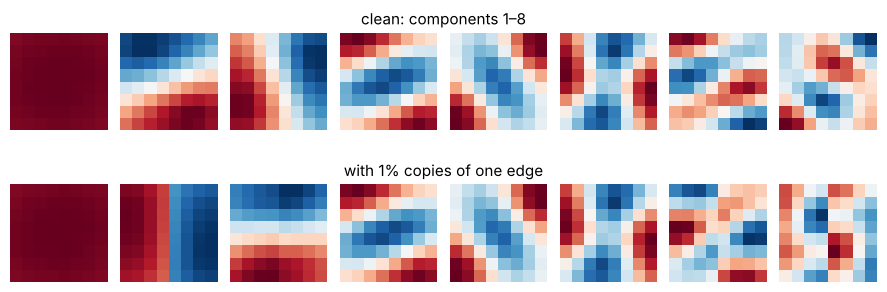

In [25]:
edge = np.zeros((P, P)); edge[:, P // 2:] = 255
Xo = np.vstack([X, np.tile(edge.ravel(), (n // 100, 1))])
mu_o = Xo.mean(axis=0)
_, So, Vto = np.linalg.svd(Xo - mu_o, full_matrices=False)
ev_o = So ** 2 / (So ** 2).sum()
cos_o = np.abs(np.sum(Vt[:8] * Vto[:8], axis=1))
print("component                    1      2      3      4      5      6      7      8")
print("|cos| clean vs with junk  ", "  ".join(f"{c:.2f}" for c in cos_o))
print("explained variance clean  ", "  ".join(f"{100*e:4.1f}" for e in ev[:8]), " %")
print("explained variance junk   ", "  ".join(f"{100*e:4.1f}" for e in ev_o[:8]), " %")

fig, axes = plt.subplots(2, 1, figsize=(9, 3.4))
Vto *= np.sign(Vto.sum(axis=1, keepdims=True) + 1e-9)
axes[0].imshow(tiles(Vt[:8], (P, P), 8, sym=True), cmap="RdBu_r", vmin=-1, vmax=1); axes[0].set_title("clean: components 1–8", fontsize=11)
axes[1].imshow(tiles(Vto[:8], (P, P), 8, sym=True), cmap="RdBu_r", vmin=-1, vmax=1); axes[1].set_title("with 1% copies of one edge", fontsize=11)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

One per cent of the data, all the same, and PC2 now *is* that edge (7.6% of the variance,
double the real PC2). The genuine gradient components get pushed down and mixed. Look at
your components before you trust them, and clean the training set — or use a robust variant.

### 12.3 — Signs, scales and what PCA is not

* **Signs are arbitrary.** $w$ and $-w$ are both eigenvectors; two libraries (or two runs)
  can flip any component. Compare components by $|\cos|$, never by equality.
* **Units matter.** PCA on features with different units (pixels and metres, NDVI and
  elevation) is dominated by whichever has the largest numbers. Standardise each feature
  first. Pixels in one image share units, so we did not.
* **PCA is unsupervised.** It keeps the directions with the most variance, not the ones
  that separate your classes — section 11.1's vegetation is in PC2. (Fisher's LDA keeps the
  directions that separate classes.)
* **PCA is linear.** A curved cloud of points needs many linear components. Autoencoders
  (Unit 3) are the nonlinear version.

---
## ✏️ Try at home

Not graded. **A** and **B** are good warm-ups for Assignment 1.

### A — Bigger patches
Repeat sections 7–8 with 16×16 patches ($d = 256$). How many components do you need for 90%
and 95%? Do the eigen-patches still look like derivatives? Is $k/d$ for 90% larger or smaller
than for 8×8 — and why?

### B — Which era?
Learn eigen-patches from the 1958 frames, then measure the test RMSE at $k = 16$ on patches
from the 1935, 1968 and 2020 images (`AL2.zip`, `eastern_pei_aerial_2020.png` converted to
gray). Which era is the 1958 basis worst at describing? What does that suggest for projects
that compare eras?

### C — Total least squares
Fit a straight line to the RANSAC inliers of L8's line toy (or any 2-D points) by PCA: the line
passes through the mean along PC1, and its normal is PC2. Compare with ordinary least squares
$y = mx + c$. When do they differ most?

### D — Fewer examples than pixels
Learn the 8×8 eigen-patches from only 20, 50, 200 and 2,000 patches. How many non-zero
singular values do you get each time, and why? How does the held-out RMSE at $k = 16$ change?
(Assignment 1 has 1,500 images of 10,000 pixels each — which regime is that?)

---
## 🔎 Explore further (optional)

**[Principal Component Analysis — Explained Visually](https://setosa.io/ev/principal-component-analysis/)** (Victor Powell and Lewis Lehe,
setosa.io). Drag the points in the 2-D plot and watch PC1 and PC2 swing round; rotate a 3-D
cloud and see it flatten onto two components; then watch PCA single out one country in a
17-dimensional table of food consumption. Ten minutes there is good intuition for sections 2–3
and for Assignment 1.

It leaves out two things this notebook covers: **centring** (section 12.1) and
**explained-variance percentages** (sections 7–8).